<a href="https://colab.research.google.com/github/gauravshukla73074-cloud/fashon_vton/blob/main/FitMirror_VTON_Test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Sun Oct 18 18:44:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    memory = torch.cuda.get_device_properties(0).total_memory
    print("GPU memory:", round(memory / (1024**3), 2), "GB")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [ ]:
!git clone https://github.com/fashn-AI/fashn-vton-1.5.git

Cloning into 'fashn-vton-1.5'...
remote: Enumerating objects: 92, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 92 (delta 20), reused 13 (delta 13), pack-reused 67 (from 1)
Receiving objects: 100% (92/92), 334.44 KiB | 33.44 MiB/s, done.
Resolving deltas: 100% (29/29), done.


In [ ]:
%cd /content/fashn-vton-1.5

/content/fashn-vton-1.5


In [ ]:
!ls -la

total 56
drwxr-xr-x 7 root root  4096 Oct 18 18:44 .
drwxr-xr-x 1 root root  4096 Oct 18 18:44 ..
drwxr-xr-x 3 root root  4096 Oct 18 18:44 examples
drwxr-xr-x 8 root root  4096 Oct 18 18:44 .git
-rw-r--r-- 1 root root   978 Oct 18 18:44 .gitignore
-rw-r--r-- 1 root root 10835 Oct 18 18:44 LICENSE
-rw-r--r-- 1 root root  1864 Oct 18 18:44 pyproject.toml
-rw-r--r-- 1 root root  4747 Oct 18 18:44 README.md
drwxr-xr-x 2 root root  4096 Oct 18 18:44 scripts
drwxr-xr-x 3 root root  4096 Oct 18 18:44 src
drwxr-xr-x 2 root root  4096 Oct 18 18:44 tests


In [ ]:
!cat README.md

# FASHN VTON v1.5: Efficient Maskless Virtual Try-On in Pixel Space

<div align="center">
  <a href="https://fashn.ai/research/vton-1-5"><img src='https://img.shields.io/badge/Project-Page-1A1A1A?style=flat' alt='Project Page'></a>&ensp;
  <a href='https://huggingface.co/fashn-ai/fashn-vton-1.5'><img src='https://img.shields.io/badge/Hugging%20Face-Model-FFD21E?style=flat&logo=HuggingFace&logoColor=FFD21E' alt='Hugging Face Model'></a>&ensp;
  <a href="https://huggingface.co/spaces/fashn-ai/fashn-vton-1.5"><img src='https://img.shields.io/badge/Hugging%20Face-Spaces-FFD21E?style=flat&logo=HuggingFace&logoColor=FFD21E' alt='Hugging Face Spaces'></a>&ensp;
  <a href=""><img src='https://img.shields.io/badge/arXiv-Coming%20Soon-b31b1b?style=flat&logo=arXiv&logoColor=b31b1b' alt='arXiv'></a>&ensp;
  <a href="LICENSE"><img src='https://img.shields.io/badge/License-Apache--2.0-gray?style=flat' alt='License'></a>
</div>

by [FASHN AI](https://fashn.ai)

Virtual try-on model that generates pho

In [ ]:
!cat pyproject.toml

[build-system]
requires = ["setuptools>=61.0", "wheel"]
build-backend = "setuptools.build_meta"

[project]
name = "fashn-vton"
version = "1.5.0"
description = "FASHN VTON v1.5"
license = {text = "Apache-2.0"}
authors = [
    {name = "FASHN AI", email = "dan@fashn.ai"}
]
keywords = ["virtual try-on", "diffusion models", "fashion", "AI", "deep learning"]
classifiers = [
    "Development Status :: 4 - Beta",
    "Intended Audience :: Developers",
    "Intended Audience :: Science/Research",
    "License :: OSI Approved :: Apache Software License",
    "Operating System :: OS Independent",
    "Programming Language :: Python :: 3",
    "Programming Language :: Python :: 3.10",
    "Programming Language :: Python :: 3.11",
    "Programming Language :: Python :: 3.12",
    "Topic :: Scientific/Engineering :: Artificial Intelligence",
    "Topic :: Scientific/Engineering :: Image Processing",
]
requires-python = ">=3.10"
dependencies = [
    "torch>=2.0.0",
    "torchvision>=0.15.0",
    "saf

In [ ]:
!ls -lah scripts/


total 24K
drwxr-xr-x 2 root root 4.0K Oct 18 18:44 .
drwxr-xr-x 7 root root 4.0K Oct 18 18:44 ..
-rw-r--r-- 1 root root  12K Oct 18 18:44 debug_masks.py
-rw-r--r-- 1 root root 3.0K Oct 18 18:44 download_weights.py


In [ ]:
!find examples -maxdepth 3 -type f

examples/basic_inference.py
examples/data/model.webp
examples/data/garment.webp


In [ ]:
%cd /content/fashn-vton-1.5

!pip install -e .

/content/fashn-vton-1.5
Obtaining file:///content/fashn-vton-1.5
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.6/255.6 MB 5.5 MB/s eta 0:00:00
  Building editable for fashn-vton (pyproject.toml) ... done
  Created wheel for fashn-vton: filename=fashn_vton-1.5.0-0.editable-py3-none-any.whl size=5771 sha256=7d005f4dcba9fb26109a187bb4614cb3ed7482b29fac1857abd5ab7e2a2b02cf
  Stored in directory: /tmp/pip-ephem-wheel-cache-hic6ayby/wheels/81/c7/ee/834de7859c1823447a7c5e12688cc45e439f96b49e9fa887ca
Successfully built fashn-vton


In [ ]:
%cd /content/fashn-vton-1.5

!python scripts/download_weights.py --weights-dir ./weights

/content/fashn-vton-1.5



model.safetensors: downloading bytes:   0% 810k/1.94G [00:01<1:09:29, 466kB/s]
model.safetensors: downloading bytes:   1% 18.7M/1.94G [00:01<02:17, 14.0MB/s, 77.3kB/s  ]
model.safetensors: reconstructing file:   1% 13.2M/1.94G [00:01<03:31, 9.15MB/s,  166kB/s  ]
model.safetensors: downloading bytes:   2% 47.4M/1.94G [00:02<00:52, 36.4MB/s, 3.50MB/s  ]
model.safetensors: downloading bytes:   3% 64.9M/1.94G [00:02<00:38, 48.7MB/s, 4.92MB/s  ]
model.safetensors: downloading bytes:   5% 96.9M/1.94G [00:02<00:25, 71.8MB/s, 7.56MB/s  ]
model.safetensors: downloading bytes:   7% 133M/1.94G [00:02<00:19, 90.8MB/s, 11.0MB/s  ]
model.safetensors: downloading bytes:   8% 148M/1.94G [00:03<00:17, 104MB/s, 11.8MB/s  ] 
model.safetensors: downloading bytes:   9% 174M/1.94G [00:03<00:15, 113MB/s, 14.0MB/s  ]
model.safetensors: downloading bytes:  11% 206M/1.94G [00:03<00:13, 129MB/s, 16.6MB/s  ]
model.safetensors: reconstructing file:   7% 146M/1.94G [00:03<00:24, 72.5MB/s,

In [ ]:
!ls -lh /content/fashn-vton-1.5/weights/

total 1.9G
drwxr-xr-x 3 root root 4.0K Oct 18 18:45 dwpose
-rw-r--r-- 1 root root 1.9G Oct 18 18:45 model.safetensors


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:
%cd /content/fashn-vton-1.5

!python examples/basic_inference.py \
    --weights-dir ./weights \
    --person-image examples/data/model.webp \
    --garment-image examples/data/garment.webp \
    --category tops

/content/fashn-vton-1.5
Loading images...
Loading pipeline from ./weights...
TryOnPipeline - INFO - Using device: cuda
TryOnPipeline - INFO - Using dtype: torch.bfloat16
TryOnPipeline - INFO - Loading TryOnModel from /content/fashn-vton-1.5/weights/model.safetensors
TryOnPipeline - INFO - TryOnModel loaded
TryOnPipeline - INFO - Loading DWPose from /content/fashn-vton-1.5/weights/dwpose
2026-10-18 18:46:41.934417361 [W:onnxruntime:Default, onnxruntime_pybind_state.cc:856 operator()] No registered plugin EP device found for 'CUDAExecutionProvider' with device_id=0
2026-10-18 18:46:43.618884239 [W:onnxruntime:Default, onnxruntime_pybind_state.cc:856 operator()] No registered plugin EP device found for 'CUDAExecutionProvider' with device_id=0
2026-10-18 18:46:43.666992422 [W:onnxruntime:, session_state.cc:1598 VerifyEachNodeIsAssignedToAnEp] Some nodes were not assigned to the preferred execution providers which may or may not have an negative impact on performance. e.g. ORT explicitly as

Image size: (576, 864)


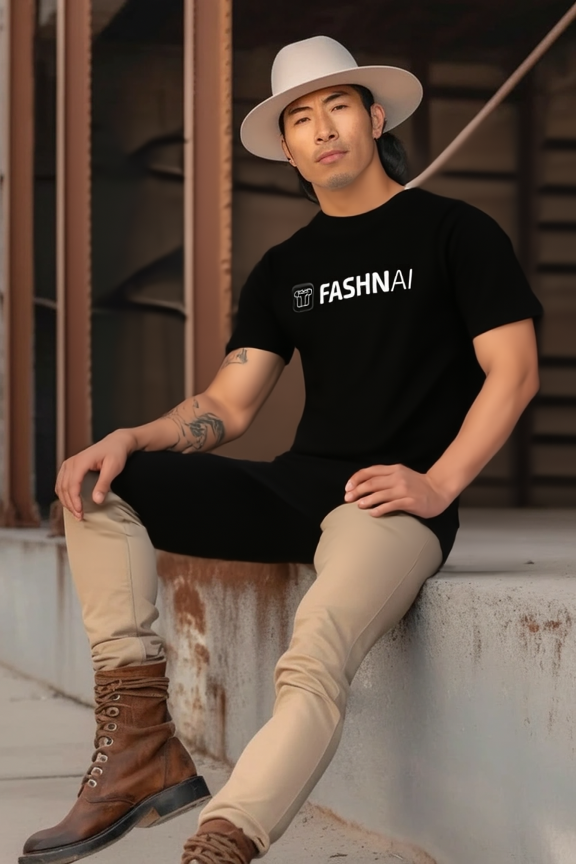

In [ ]:
from PIL import Image
from IPython.display import display

image_path = "/content/fashn-vton-1.5/outputs/output_00.png"

result = Image.open(image_path)

print("Image size:", result.size)

display(result)

In [ ]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))

Saving Screenshot (39).png to Screenshot (39).png
Saving Screenshot 2025-10-15 155651.png to Screenshot 2025-10-15 155651.png
Uploaded files: ['Screenshot (39).png', 'Screenshot 2025-10-15 155651.png']


In [ ]:
import os

for filename in uploaded.keys():
    print(filename, "->", os.path.exists(filename))

Screenshot (39).png -> True
Screenshot 2025-10-15 155651.png -> True


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for filename in files:
        if filename in [
            "Screenshot 2025-10-15 155651.png",
            "Screenshot (39) (4).png"
        ]:
            print(os.path.join(root, filename))

/content/fashn-vton-1.5/Screenshot 2025-10-15 155651.png


Person image:


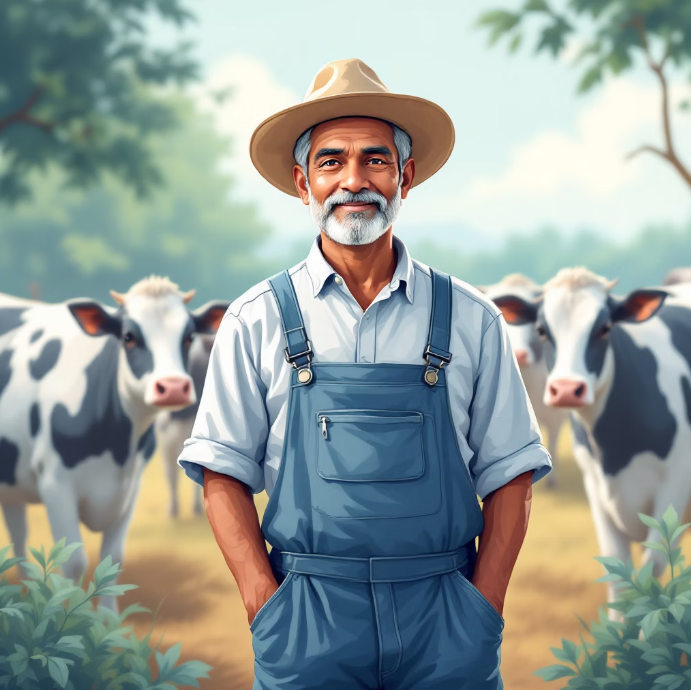

Garment image:


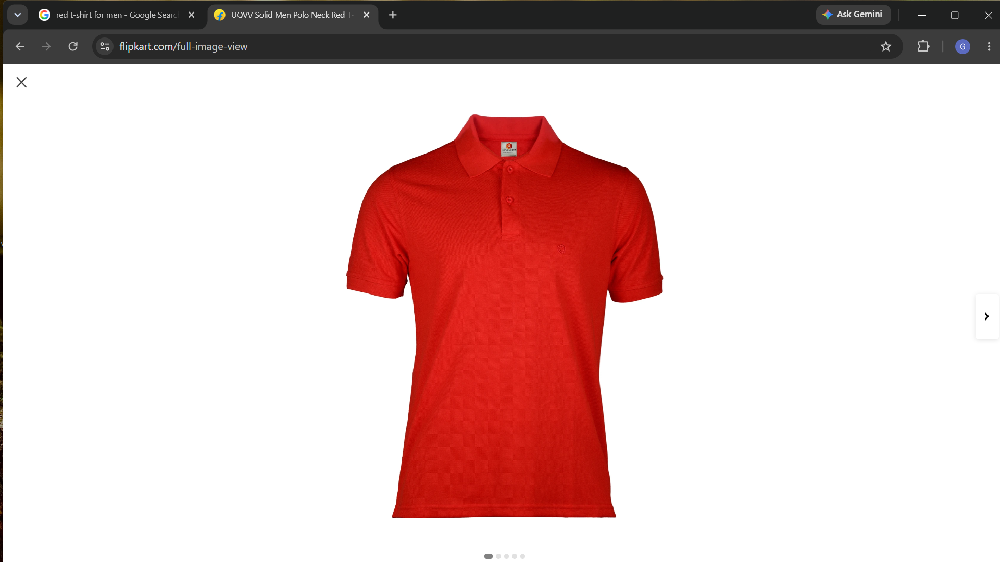

In [ ]:
from PIL import Image
from IPython.display import display

person_path = "/content/fashn-vton-1.5/Screenshot 2025-10-15 155651.png"
garment_path = "/content/fashn-vton-1.5/Screenshot (39).png"

person = Image.open(person_path).convert("RGB")
garment = Image.open(garment_path).convert("RGB")

print("Person image:")
display(person)

print("Garment image:")
display(garment)

TryOnPipeline - INFO - Running inference with 30 timesteps...


Sampling:   0%|          | 0/30 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


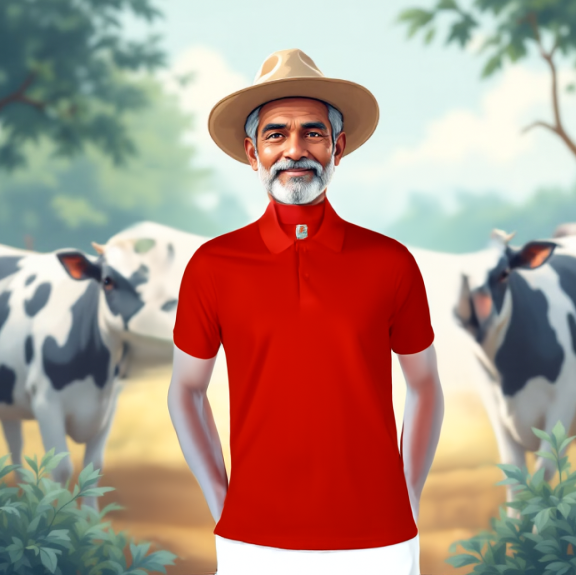

In [ ]:
result = pipeline(
    person_image=person,
    garment_image=garment,
    category="tops"
)

display(result.images[0])

In [ ]:
from google.colab import files

uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

Saving Screenshot 2026-10-17 015600.png to Screenshot 2026-10-17 015600 (1).png
Saving Screenshot 2026-10-17 015857.png to Screenshot 2026-10-17 015857.png
Uploaded files: ['Screenshot 2026-10-17 015600 (1).png', 'Screenshot 2026-10-17 015857.png']


In [ ]:
import os

for root, dirs, filenames in os.walk("/content"):
    for filename in filenames:
        if filename in [
            "Screenshot 2026-10-17 015857.png",
            "Screenshot 2026-10-17 015600.png"
        ]:
            print(os.path.join(root, filename))

/content/fashn-vton-1.5/Screenshot 2026-10-17 015600.png
/content/fashn-vton-1.5/Screenshot 2026-10-17 015857.png


Image 1:


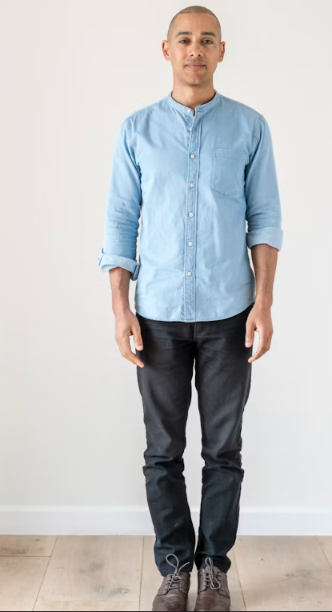

Image 2:


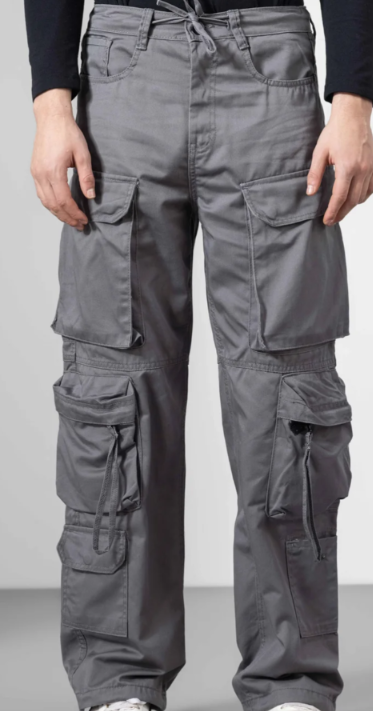

In [ ]:
from PIL import Image
from IPython.display import display

image1_path = "/content/fashn-vton-1.5/Screenshot 2026-10-17 015600.png"
image2_path = "/content/fashn-vton-1.5/Screenshot 2026-10-17 015857.png"

print("Image 1:")
display(Image.open(image1_path))

print("Image 2:")
display(Image.open(image2_path))

In [ ]:
person_path = image1_path
garment_path = image2_path

person = Image.open(person_path).convert("RGB")
garment = Image.open(garment_path).convert("RGB")

TryOnPipeline - INFO - Running inference with 30 timesteps...


Sampling:   0%|          | 0/30 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


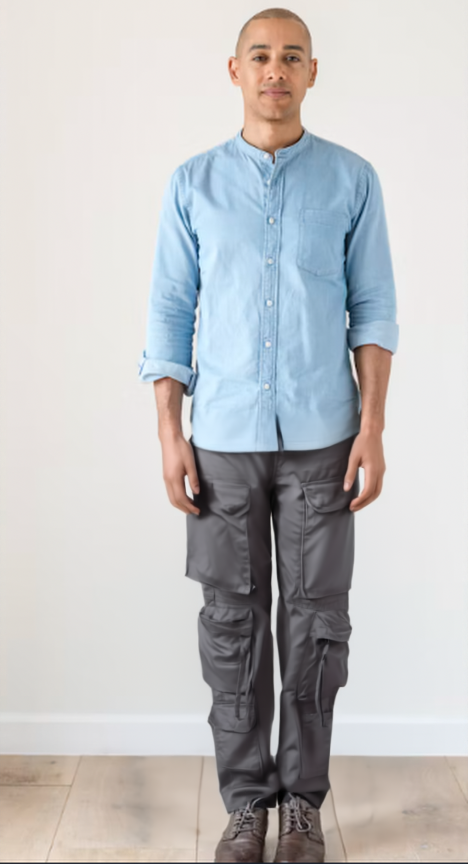

In [ ]:
result = pipeline(
    person_image=person,
    garment_image=garment,
    category="bottoms"
)

display(result.images[0])

In [ ]:
from google.colab import files
import os

output_path = "/content/fashn-vton-1.5/outputs/fitmirror_30_steps.png"

os.makedirs(os.path.dirname(output_path), exist_ok=True)

# Save the latest generated image
result_10_new.images[0].save(output_path)

# Download to your laptop
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%cd /content/fashn-vton-1.5

/content/fashn-vton-1.5


In [ ]:
import os

print("Project exists:", os.path.exists("/content/fashn-vton-1.5"))
print("Source folder exists:", os.path.exists("/content/fashn-vton-1.5/src"))
print("Model weights exist:", os.path.exists("/content/fashn-vton-1.5/weights/model.safetensors"))


Project exists: True
Source folder exists: True
Model weights exist: True


In [ ]:
import sys
import os

project_path = "/content/fashn-vton-1.5"
src_path = os.path.join(project_path, "src")

sys.path.insert(0, src_path)

print("Source path added:", src_path)
print("Source contents:", os.listdir(src_path))

Source path added: /content/fashn-vton-1.5/src
Source contents: ['fashn_vton', 'fashn_vton.egg-info']


In [ ]:
from fashn_vton import TryOnPipeline

print("TryOnPipeline imported successfully!")

TryOnPipeline imported successfully!


In [ ]:
pipeline = TryOnPipeline(
    weights_dir="/content/fashn-vton-1.5/weights"
)

print("Model loaded successfully!")

TryOnPipeline - INFO - Using device: cuda
TryOnPipeline - INFO - Using dtype: torch.bfloat16
TryOnPipeline - INFO - Loading TryOnModel from /content/fashn-vton-1.5/weights/model.safetensors
TryOnPipeline - INFO - TryOnModel loaded
TryOnPipeline - INFO - Loading DWPose from /content/fashn-vton-1.5/weights/dwpose
TryOnPipeline - INFO - DWPose loaded
TryOnPipeline - INFO - Loading FashnHumanParser


Loading weights:   0%|          | 0/930 [00:00<?, ?it/s]

TryOnPipeline - INFO - FashnHumanParser loaded


Model loaded successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

print("\nUploaded filenames:")
for filename in uploaded.keys():
    print(filename)

Saving Screenshot 2026-10-17 012131.png to Screenshot 2026-10-17 012131 (1).png
Saving Screenshot 2026-10-17 015646.png to Screenshot 2026-10-17 015646 (1).png

Uploaded filenames:
Screenshot 2026-10-17 012131 (1).png
Screenshot 2026-10-17 015646 (1).png


Person image:


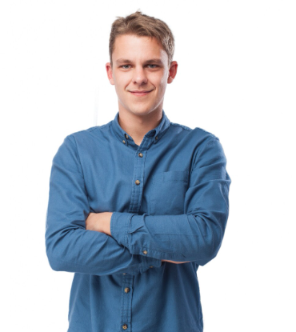

Garment image:


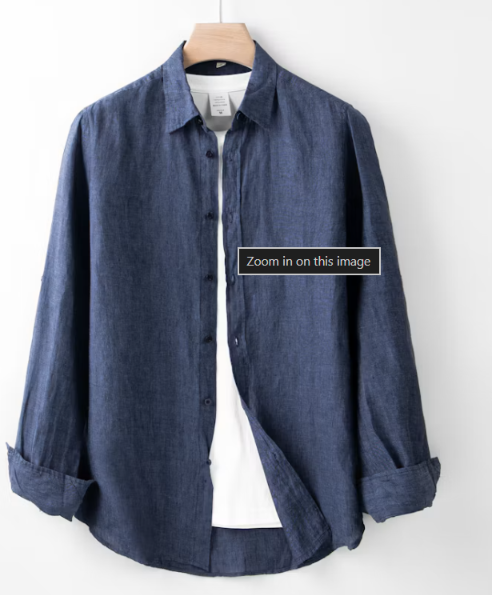

In [ ]:
from PIL import Image
from IPython.display import display

filenames = list(uploaded.keys())

if len(filenames) < 2:
    print("Please upload both the person image and the garment image.")
else:
    person_test = Image.open(filenames[0]).convert("RGB")
    garment_test = Image.open(filenames[1]).convert("RGB")

    print("Person image:")
    display(person_test)

    print("Garment image:")
    display(garment_test)

TryOnPipeline - INFO - Running inference with 30 timesteps...


Sampling:   0%|          | 0/30 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


Generation time: 7.09 minutes


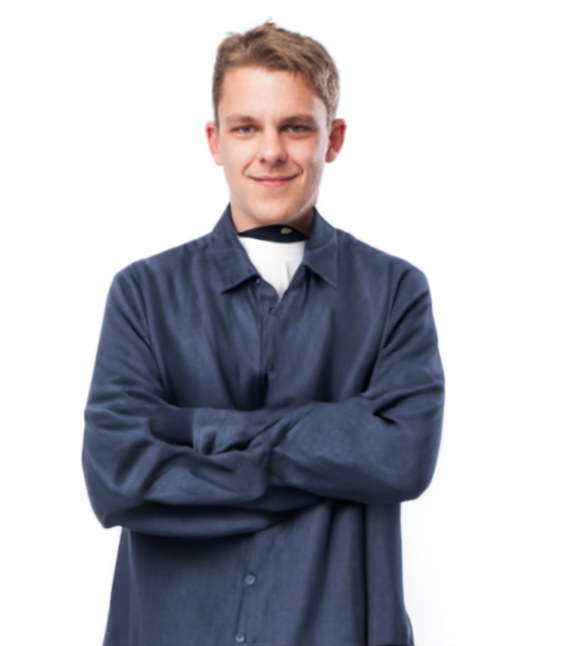

In [ ]:
import time
from IPython.display import display

start_time = time.time()

test_result = pipeline(
    person_image=person_test,
    garment_image=garment_test,
    category="tops"
)

print(f"Generation time: {(time.time() - start_time) / 60:.2f} minutes")
display(test_result.images[0])

In [ ]:
from google.colab import files

uploaded_new = files.upload()

print("Uploaded files:", list(uploaded_new.keys()))

Saving Screenshot 2026-10-19 011551.png to Screenshot 2026-10-19 011551 (1).png
Saving Screenshot 2026-10-19 011724.png to Screenshot 2026-10-19 011724 (1).png
Uploaded files: ['Screenshot 2026-10-19 011551 (1).png', 'Screenshot 2026-10-19 011724 (1).png']


New person image:


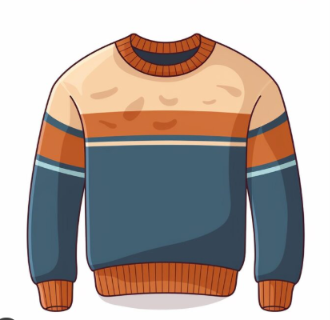

New garment image:


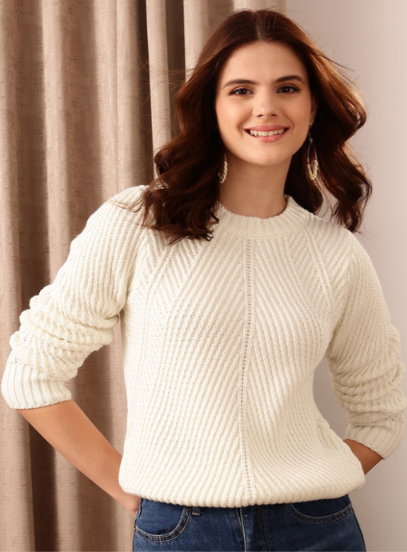

In [ ]:
from PIL import Image
from IPython.display import display

filenames_new = list(uploaded_new.keys())

if len(filenames_new) < 2:
    print("Please upload both images.")
else:
    person_test_2 = Image.open(filenames_new[0]).convert("RGB")
    garment_test_2 = Image.open(filenames_new[1]).convert("RGB")

    print("New person image:")
    display(person_test_2)

    print("New garment image:")
    display(garment_test_2)

In [ ]:
person_test_2, garment_test_2 = garment_test_2, person_test_2

TryOnPipeline - INFO - Running inference with 30 timesteps...


Sampling:   0%|          | 0/30 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


Generation time: 7.11 minutes


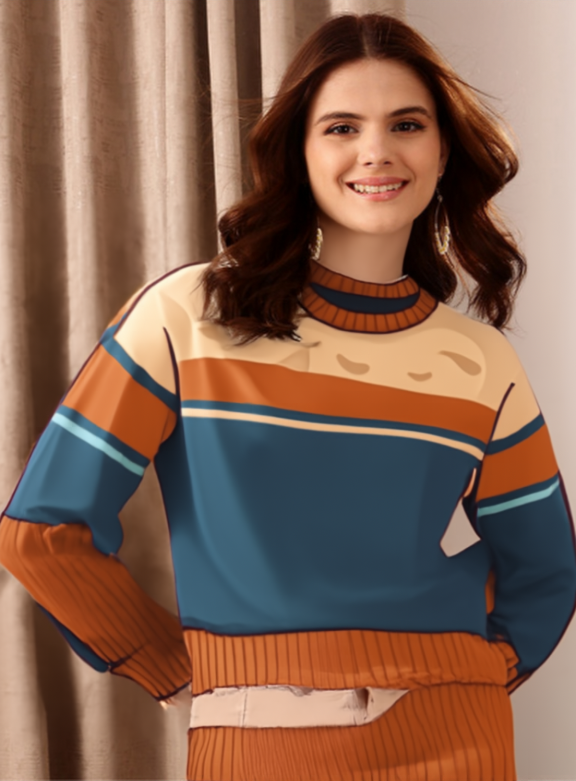

In [ ]:
import time
from IPython.display import display

start_time = time.time()

result_2 = pipeline(
    person_image=person_test_2,
    garment_image=garment_test_2,
    category="tops"
)

print(f"Generation time: {(time.time() - start_time) / 60:.2f} minutes")

display(result_2.images[0])

In [ ]:
import inspect

print(inspect.signature(pipeline.__call__))

(person_image: PIL.Image.Image, garment_image: PIL.Image.Image, category: Literal['tops', 'bottoms', 'one-pieces'], garment_photo_type: Literal['model', 'flat-lay'] = 'model', num_samples: int = 1, num_timesteps: int = 30, guidance_scale: float = 1.5, skip_cfg_last_n_steps: int = 1, seed: int = 42, segmentation_free: bool = True) -> fashn_vton.pipeline.PipelineOutput


In [ ]:
print(inspect.getsource(pipeline.__call__))

    @torch.inference_mode()
    def __call__(
        self,
        person_image: Image.Image,
        garment_image: Image.Image,
        category: Literal["tops", "bottoms", "one-pieces"],
        garment_photo_type: Literal["model", "flat-lay"] = "model",
        num_samples: int = 1,
        num_timesteps: int = 30,
        guidance_scale: float = 1.5,
        skip_cfg_last_n_steps: int = 1,
        seed: int = 42,
        segmentation_free: bool = True,
    ) -> PipelineOutput:
        """
        Run virtual try-on inference.

        Args:
            person_image: RGB image of the person to dress.
            garment_image: RGB image of the garment (model photo or flat-lay).
            category: Garment category - "tops", "bottoms", or "one-pieces".
            garment_photo_type: "model" if garment is worn by a person,
                "flat-lay" for product shots on plain backgrounds.
            num_samples: Number of output images to generate (1-4).
            num_timestep

In [ ]:
from google.colab import files

uploaded_new = files.upload()

print("Uploaded files:", list(uploaded_new.keys()))

Saving Screenshot 2026-10-19 011724.png to Screenshot 2026-10-19 011724 (2).png
Saving Screenshot 2026-10-19 021106.png to Screenshot 2026-10-19 021106.png
Uploaded files: ['Screenshot 2026-10-19 011724 (2).png', 'Screenshot 2026-10-19 021106.png']


Person image:


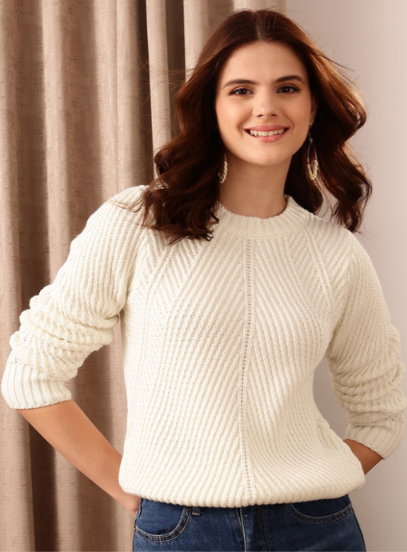

Garment image:


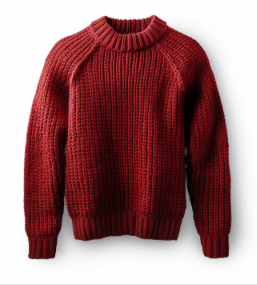

In [ ]:
from PIL import Image
from IPython.display import display

filenames = list(uploaded_new.keys())

if len(filenames) < 2:
    print("Please upload both images.")
else:
    person_test_3 = Image.open(filenames[0]).convert("RGB")
    garment_test_3 = Image.open(filenames[1]).convert("RGB")

    print("Person image:")
    display(person_test_3)

    print("Garment image:")
    display(garment_test_3)

TryOnPipeline - INFO - Running inference with 20 timesteps...


Sampling:   0%|          | 0/20 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


Generation time: 4.69 minutes


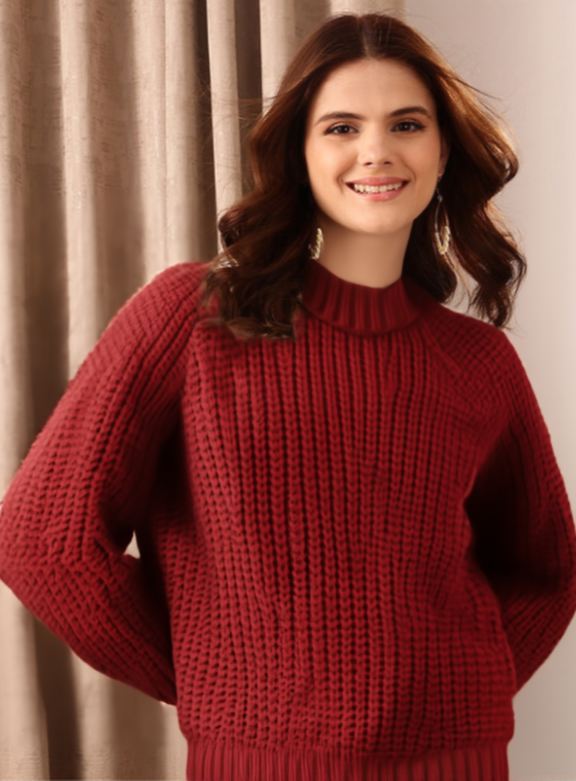

In [ ]:
import time
from IPython.display import display

start_time = time.time()

result_20 = pipeline(
    person_image=person_test_3,
    garment_image=garment_test_3,
    category="tops",
    num_timesteps=20
)

elapsed = (time.time() - start_time) / 60

print(f"Generation time: {elapsed:.2f} minutes")
display(result_20.images[0])

TryOnPipeline - INFO - Running inference with 15 timesteps...


Sampling:   0%|          | 0/15 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


Generation time: 3.56 minutes


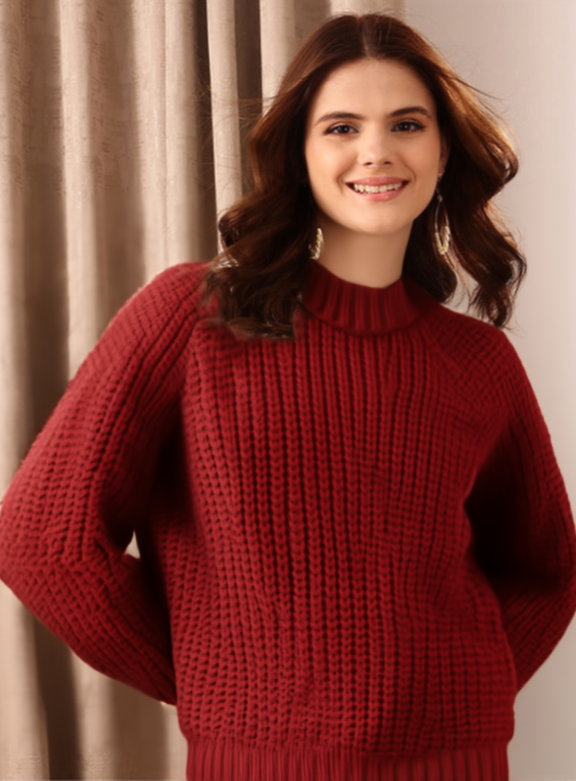

In [ ]:
import time
from IPython.display import display

start_time = time.time()

result_15 = pipeline(
    person_image=person_test_3,
    garment_image=garment_test_3,
    category="tops",
    num_timesteps=15
)

elapsed = (time.time() - start_time) / 60

print(f"Generation time: {elapsed:.2f} minutes")
display(result_15.images[0])

TryOnPipeline - INFO - Running inference with 10 timesteps...


Sampling:   0%|          | 0/10 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


Generation time: 2.38 minutes


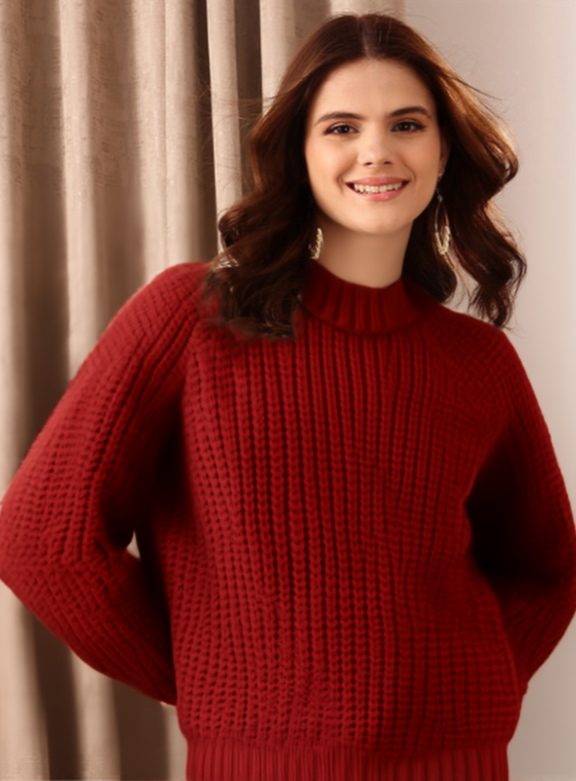

In [ ]:
import time
from IPython.display import display

start_time = time.time()

result_10 = pipeline(
    person_image=person_test_3,
    garment_image=garment_test_3,
    category="tops",
    num_timesteps=10
)

elapsed = (time.time() - start_time) / 60

print(f"Generation time: {elapsed:.2f} minutes")
display(result_10.images[0])

In [ ]:
from google.colab import files

uploaded_4 = files.upload()

print("Uploaded files:", list(uploaded_4.keys()))

Saving Screenshot 2026-10-17 015600.png to Screenshot 2026-10-17 015600 (2).png
Saving Screenshot 2026-10-17 015857.png to Screenshot 2026-10-17 015857 (1).png
Uploaded files: ['Screenshot 2026-10-17 015600 (2).png', 'Screenshot 2026-10-17 015857 (1).png']


In [ ]:
import os

for root, dirs, files_list in os.walk("/content"):
    for filename in files_list:
        if "015600" in filename or "015857" in filename:
            print(os.path.join(root, filename))

/content/fashn-vton-1.5/Screenshot 2026-10-17 015600.png
/content/fashn-vton-1.5/Screenshot 2026-10-17 015857 (1).png
/content/fashn-vton-1.5/Screenshot 2026-10-17 015600 (1).png
/content/fashn-vton-1.5/Screenshot 2026-10-17 015600 (2).png
/content/fashn-vton-1.5/Screenshot 2026-10-17 015857.png


Person image:


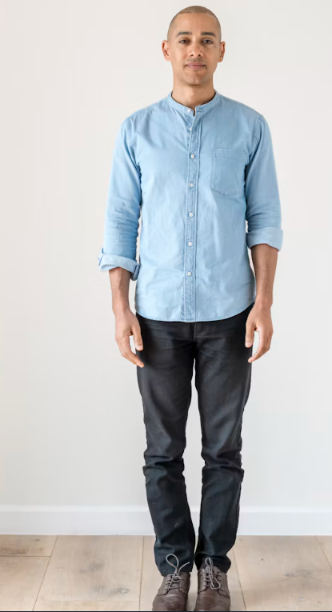

Garment image:


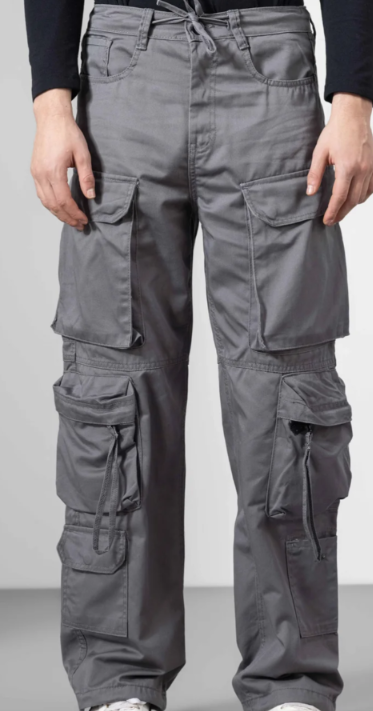

In [ ]:
from PIL import Image
from IPython.display import display

person_test_4 = Image.open(
    "/content/fashn-vton-1.5/Screenshot 2026-10-17 015600 (2).png"
).convert("RGB")

garment_test_4 = Image.open(
    "/content/fashn-vton-1.5/Screenshot 2026-10-17 015857 (1).png"
).convert("RGB")

print("Person image:")
display(person_test_4)

print("Garment image:")
display(garment_test_4)

TryOnPipeline - INFO - Running inference with 10 timesteps...


Sampling:   0%|          | 0/10 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


Generation time: 2.39 minutes


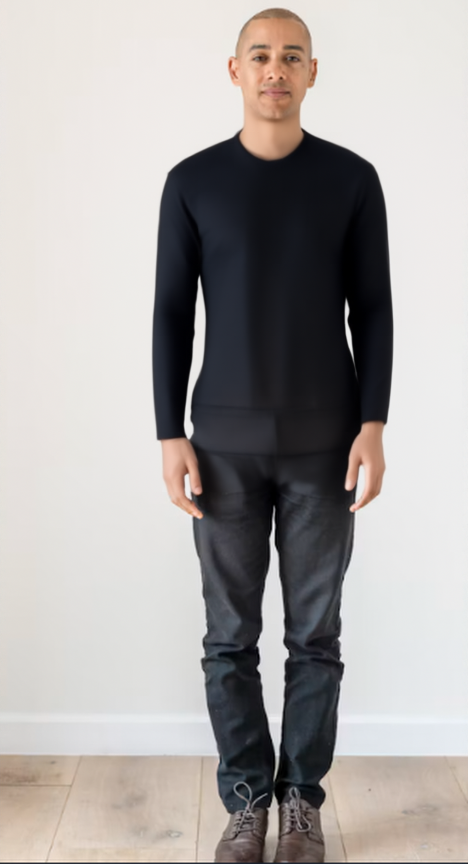

In [ ]:
import time
from IPython.display import display

start_time = time.time()

result_10_new = pipeline(
    person_image=person_test_4,
    garment_image=garment_test_4,
    category="tops",
    num_timesteps=10
)

elapsed = (time.time() - start_time) / 60

print(f"Generation time: {elapsed:.2f} minutes")
display(result_10_new.images[0])

TryOnPipeline - INFO - Running inference with 10 timesteps...


Sampling:   0%|          | 0/10 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


Generation time: 2.38 minutes


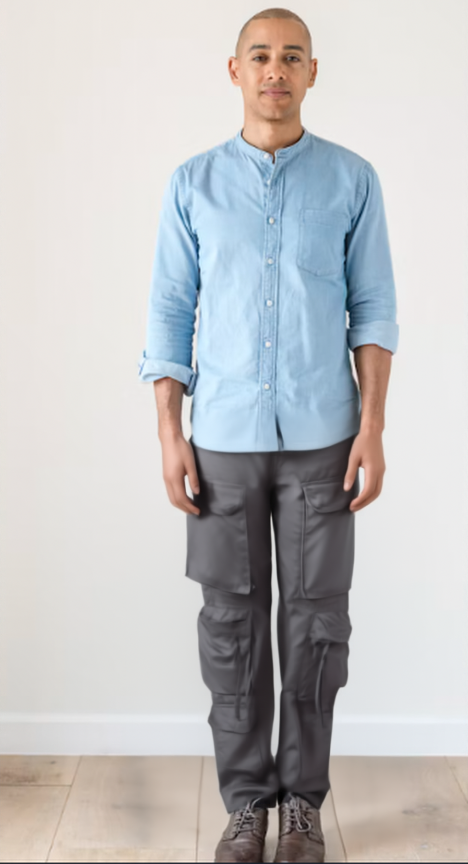

In [ ]:
import time
from IPython.display import display

start_time = time.time()

result_10_new = pipeline(
    person_image=person_test_4,
    garment_image=garment_test_4,
    category="bottoms",
    num_timesteps=10
)

elapsed = (time.time() - start_time) / 60

print(f"Generation time: {elapsed:.2f} minutes")
display(result_10_new.images[0])

In [ ]:
from google.colab import files
import os

output_path = "/content/fashn-vton-1.5/outputs/fitmirror_10_steps.png"

os.makedirs(os.path.dirname(output_path), exist_ok=True)

# Save the 10-timestep result
result_10_new.images[0].save(output_path)

# Download it to your laptop
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Allocated GPU memory:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )

GPU available: True
GPU: Tesla T4
Allocated GPU memory: 2.07 GB


In [ ]:
import onnxruntime as ort

print("ONNX Runtime version:", ort.__version__)
print("\nAvailable execution providers:")

for provider in ort.get_available_providers():
    print("-", provider)

ONNX Runtime version: 1.31.0

Available execution providers:
- TensorrtExecutionProvider
- CUDAExecutionProvider
- CPUExecutionProvider


In [ ]:
import onnxruntime as ort

print("Available providers:", ort.get_available_providers())

pipeline_pose = pipeline.pose_model

print("\nPose model type:", type(pipeline_pose))
print("Pose model attributes:")

for attr in dir(pipeline_pose):
    if "session" in attr.lower() or "provider" in attr.lower():
        print(attr)

Available providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']

Pose model type: <class 'fashn_vton.dwpose.dwpose.DWposeDetector'>
Pose model attributes:


In [ ]:
print("POSE DETECTOR")
print(vars(pipeline.pose_model).keys())

print("\nHUMAN PARSER")
print(vars(pipeline.hp_model).keys())

POSE DETECTOR
dict_keys(['pose_estimation'])

HUMAN PARSER
dict_keys(['device', 'model'])


In [ ]:
pose_estimator = pipeline.pose_model.pose_estimation

print("Pose estimator type:", type(pose_estimator))
print("\nAttributes:")

for attr, value in vars(pose_estimator).items():
    print(f"{attr}: {type(value)}")

Pose estimator type: <class 'fashn_vton.dwpose.wholebody.Wholebody'>

Attributes:
session_det: <class 'onnxruntime.capi.onnxruntime_inference_collection.InferenceSession'>
session_pose: <class 'onnxruntime.capi.onnxruntime_inference_collection.InferenceSession'>


In [ ]:
pose_estimator = pipeline.pose_model.pose_estimation

print("Detection session providers:")
print(pose_estimator.session_det.get_providers())

print("\nPose estimation session providers:")
print(pose_estimator.session_pose.get_providers())

Detection session providers:
['CUDAExecutionProvider', 'CPUExecutionProvider']

Pose estimation session providers:
['CUDAExecutionProvider', 'CPUExecutionProvider']


In [ ]:
print("Human parser device:", pipeline.hp_model.device)

print("Model type:", type(pipeline.hp_model.model))

Human parser device: cuda
Model type: <class 'transformers.models.segformer.modeling_segformer.SegformerForSemanticSegmentation'>


In [ ]:
import time
import torch

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

start_time = time.perf_counter()

result_benchmark = pipeline(
    person_image=person_test_4,
    garment_image=garment_test_4,
    category="tops",
    num_timesteps=10
)

torch.cuda.synchronize()

total_time = time.perf_counter() - start_time

print(f"Total generation time: {total_time / 60:.2f} minutes")
print(
    f"Peak GPU memory: "
    f"{torch.cuda.max_memory_allocated() / 1024**3:.2f} GB"
)

TryOnPipeline - INFO - Running inference with 10 timesteps...


Sampling:   0%|          | 0/10 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


Total generation time: 2.40 minutes
Peak GPU memory: 10.90 GB


In [ ]:
import inspect

print(inspect.signature(pipeline._sample))
print(inspect.getsource(pipeline._sample))

(*, ca_images: torch.Tensor, garment_images: torch.Tensor, person_poses: torch.Tensor, garment_poses: torch.Tensor, garment_categories: torch.Tensor, num_timesteps: int = 30, time_shift_mu: float = 1.5, guidance_scale: float = 1.5, skip_cfg_last_n_steps: int = 1, use_tqdm: bool = True) -> List[PIL.Image.Image]
    @torch.inference_mode()
    def _sample(
        self,
        *,
        ca_images: torch.Tensor,
        garment_images: torch.Tensor,
        person_poses: torch.Tensor,
        garment_poses: torch.Tensor,
        garment_categories: torch.Tensor,
        num_timesteps: int = 30,
        time_shift_mu: float = 1.5,
        guidance_scale: float = 1.5,
        skip_cfg_last_n_steps: int = 1,
        use_tqdm: bool = True,
    ) -> List[Image.Image]:
        """Euler sampling with CFG."""
        device, dtype = ca_images.device, ca_images.dtype
        batch_size = ca_images.shape[0]

        # Init noisy images
        c, h, w = self.tryon_model.channels_in, *self.tryon_m

In [ ]:
import inspect

print(inspect.signature(pipeline.tryon_model.forward_for_cfg))
print(inspect.getsource(pipeline.tryon_model.forward_for_cfg))

(*args, **kwargs)
    def forward_for_cfg(self, *args, **kwargs):
        # cleanup kwargs
        kwargs = compact(kwargs)

        # infer batch size from the first tensor argument
        noisy_images = args[0]
        batch_size = noisy_images.shape[0]

        # duplicate all tensor arguments and keyword arguments
        duplicated_args = [torch.cat([arg, arg], dim=0) if isinstance(arg, torch.Tensor) else arg for arg in args]
        duplicated_kwargs = {
            k: torch.cat([v, v], dim=0) if isinstance(v, torch.Tensor) else v for k, v in kwargs.items()
        }

        # prepare cond drop masks for the duplicated inputs
        mask = torch.cat(
            [
                torch.ones(batch_size, device=noisy_images.device, dtype=torch.bool),
                torch.zeros(batch_size, device=noisy_images.device, dtype=torch.bool),
            ],
            dim=0,
        )

        # add cond_drop_probs to duplicated_kwargs
        duplicated_kwargs["mask"] = mask

       

In [ ]:
import inspect

print(inspect.signature(pipeline.tryon_model.forward))
print(inspect.getsource(pipeline.tryon_model.forward))

(x, times, ca_images, garment_images, person_poses, garment_poses, mask: Optional[torch.Tensor] = None, guidance: Optional[torch.Tensor] = None, garment_categories: Optional[torch.Tensor] = None)
    def forward(
        self,
        x,
        times,
        ca_images,
        garment_images,
        person_poses,
        garment_poses,
        mask: Optional[torch.Tensor] = None,
        guidance: Optional[torch.Tensor] = None,
        garment_categories: Optional[torch.Tensor] = None,
    ):
        ###################### CLASSIFIER FREE GUIDANCE ######################

        batch_size, device = x.shape[0], x.device

        # if mask is not provided, create a boolean mask of all true
        if not exists(mask):
            mask = torch.ones(batch_size, device=device, dtype=torch.bool)

        ####################### 2D IMAGES TO SEQUENCE ########################

        ca_images = apply_conditional_dropout(ca_images, mask)
        person_poses = apply_conditional_dropout(pe

In [ ]:
model = pipeline.tryon_model

print("Double blocks:", len(model.double_blocks))
print("Single blocks:", len(model.single_blocks))
print("Patch mixer enabled:", model.use_patch_mixer)
print("Patch mixer blocks:", len(model.x_patch_mixer))

print("Model dtype:", next(model.parameters()).dtype)
print("GPU:", torch.cuda.get_device_name(0))

Double blocks: 8
Single blocks: 16
Patch mixer enabled: True
Patch mixer blocks: 4
Model dtype: torch.bfloat16
GPU: Tesla T4


In [ ]:
import time
import torch

device = torch.device("cuda")

x = torch.randn((2048, 2048), device=device, dtype=torch.bfloat16)

# Warm up the GPU
for _ in range(3):
    y = x @ x

torch.cuda.synchronize()
start = time.perf_counter()

for _ in range(10):
    y = x @ x

torch.cuda.synchronize()
elapsed = time.perf_counter() - start

print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Average matrix multiplication time: {elapsed / 10:.4f} seconds")
print(f"Allocated GPU memory: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

GPU: Tesla T4
Average matrix multiplication time: 0.0106 seconds
Allocated GPU memory: 2.08 GB


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))
print("GPU capability:", torch.cuda.get_device_capability(0))
print("torch.compile available:", hasattr(torch, "compile"))

PyTorch: 2.11.0+cu130
CUDA: 13.0
GPU: Tesla T4
GPU capability: (7, 5)
torch.compile available: True


In [ ]:
import inspect

print(inspect.signature(pipeline.tryon_model.forward))
print("Model training mode:", pipeline.tryon_model.training)

(x, times, ca_images, garment_images, person_poses, garment_poses, mask: Optional[torch.Tensor] = None, guidance: Optional[torch.Tensor] = None, garment_categories: Optional[torch.Tensor] = None)
Model training mode: False


In [ ]:
import time
import torch

pipeline.tryon_model.eval()

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

start = time.perf_counter()

result_baseline = pipeline(
    person_image=person_test_4,
    garment_image=garment_test_4,
    category="tops",
    num_timesteps=10,
)

torch.cuda.synchronize()

baseline_seconds = time.perf_counter() - start
baseline_memory = torch.cuda.max_memory_allocated() / 1024**3

print(f"Baseline time: {baseline_seconds:.2f} seconds")
print(f"Peak GPU memory: {baseline_memory:.2f} GB")

TryOnPipeline - INFO - Running inference with 10 timesteps...


Sampling:   0%|          | 0/10 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


Baseline time: 143.28 seconds
Peak GPU memory: 10.92 GB


In [ ]:
import torch

model = pipeline.tryon_model

print("Model device:", next(model.parameters()).device)
print("Model dtype:", next(model.parameters()).dtype)
print("CUDA memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
print("CUDA memory reserved:",
      round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")
print("CUDA memory free:",
      round((torch.cuda.get_device_properties(0).total_memory
             - torch.cuda.memory_reserved()) / 1024**3, 2), "GB")

Model device: cuda:0
Model dtype: torch.bfloat16
CUDA memory allocated: 2.08 GB
CUDA memory reserved: 13.43 GB
CUDA memory free: 1.14 GB


In [ ]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

print(f"Allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
print(f"Reserved:  {torch.cuda.memory_reserved() / 1024**3:.2f} GB")
print(f"Peak:      {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")

Allocated: 2.08 GB
Reserved:  2.24 GB
Peak:      10.92 GB


In [ ]:
import inspect

model = pipeline.tryon_model

print("Double block class:")
print(type(model.double_blocks[0]))

print("\nDouble block forward:")
print(inspect.getsource(type(model.double_blocks[0]).forward))

Double block class:
<class 'fashn_vton.tryon_mmdit.DoubleStreamBlock'>

Double block forward:
    def forward(self, img: Tensor, txt: Tensor, vec: Tensor, pe: Tensor) -> tuple[Tensor, Tensor]:
        img_mod1, img_mod2 = self.img_mod(vec)
        txt_mod1, txt_mod2 = self.txt_mod(vec)

        # prepare image for attention
        img_modulated = self.img_norm1(img)
        img_modulated = (1 + img_mod1.scale) * img_modulated + img_mod1.shift
        img_qkv = self.img_attn.qkv(img_modulated)
        img_q, img_k, img_v = rearrange(img_qkv, "B L (K H D) -> K B H L D", K=3, H=self.num_heads)
        img_q, img_k = self.img_attn.norm(img_q, img_k, img_v)

        # prepare txt for attention
        txt_modulated = self.txt_norm1(txt)
        txt_modulated = (1 + txt_mod1.scale) * txt_modulated + txt_mod1.shift
        txt_qkv = self.txt_attn.qkv(txt_modulated)
        txt_q, txt_k, txt_v = rearrange(txt_qkv, "B L (K H D) -> K B H L D", K=3, H=self.num_heads)
        txt_q, txt_k = self.

In [ ]:
import inspect
import fashn_vton.tryon_mmdit as mmdit

print("Attention function:")
print(inspect.getsource(mmdit.attention))

Attention function:
def attention(q: Tensor, k: Tensor, v: Tensor, pe: Tensor) -> Tensor:
    q, k = apply_rope(q, k, pe)
    x = _attn_processor(q, k, v)
    x = rearrange(x, "B H L D -> B L (H D)")

    return x



In [ ]:
import inspect
import fashn_vton.tryon_mmdit as mmdit

print("Processor:", mmdit._attn_processor)
print("Module:", mmdit._attn_processor.__module__)

try:
    print(inspect.getsource(mmdit._attn_processor))
except (TypeError, OSError):
    print("Source code is unavailable. Inspect the processor's module instead.")

Processor: <function _attn_processor at 0x7f41499ce7a0>
Module: fashn_vton.tryon_mmdit
def _attn_processor(q: Tensor, k: Tensor, v: Tensor) -> Tensor:
    """Scaled dot product attention using PyTorch native implementation."""
    return torch.nn.functional.scaled_dot_product_attention(q, k, v)



In [ ]:
import torch

print("Flash SDP enabled:",
      torch.backends.cuda.flash_sdp_enabled())

print("Memory-efficient SDP enabled:",
      torch.backends.cuda.mem_efficient_sdp_enabled())

print("Math SDP enabled:",
      torch.backends.cuda.math_sdp_enabled())

Flash SDP enabled: True
Memory-efficient SDP enabled: True
Math SDP enabled: True
